# Capstone Exploratory Data Analysis: DataCo Supply Chain Dataset

## Project Topic
**Weather-Driven Supply Chain Delay Analysis and Risk Assessment**

## Research Question
**How do weather conditions influence shipment delays for orders delivered within the United States?**

This notebook begins the exploratory data analysis (EDA) for the capstone project. The purpose of this notebook is to understand the structure, quality, scope, and usefulness of the DataCo supply chain dataset before integrating weather data from NOAA.

The EDA supports the Data Engineering capstone by documenting the initial data extraction, inspection, profiling, and preparation steps that will later feed into the ETL pipeline.


## 1. Import Libraries

The libraries below will be used to inspect the dataset, evaluate data quality, create initial visualizations, and prepare the data for later transformation and loading into a database.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

The primary dataset is the **DataCo Smart Supply Chain Dataset** downloaded from Kaggle. This dataset contains order, customer, product, shipping, and delivery information that can be used to evaluate late delivery risk and shipment performance.


In [2]:
DATA_PATH = Path(r"C:\Users\tnpen\Documents\WGU Data Engineering, MS\D610 DE Captstone\project data\DataCoSupplyChainDataset.csv")

df = pd.read_csv(DATA_PATH, encoding="latin1")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
df.head()

Rows: 180,519
Columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 3. Review Column Names and Data Types

This step identifies available fields and helps determine which variables may be useful for shipment delay analysis, geographic filtering, and later weather integration.


In [3]:
# Display column names
df.columns.tolist()

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Id',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'Order Customer Id',
 'order date (DateOrders)',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Image',
 'Product Name',
 'Product P

In [4]:
# Review data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

## 4. Initial Data Quality Profile

This step checks missing values and duplicate records. These findings will be useful for the Task 2 report section on data extraction and preparation.


In [5]:
# Missing value summary
missing_summary = (
    df.isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "missing_count"})
)

missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(df) * 100).round(2)
missing_summary.sort_values("missing_percent", ascending=False).head(20)

,column,missing_count,missing_percent
46,Product Description,180519,100.00
43,Order Zipcode,155679,86.24
2,Days for shipment (scheduled),0,0.00
1,Days for shipping (real),0,0.00
0,Type,0,0.00
5,Delivery Status,0,0.00
6,Late_delivery_risk,0,0.00
7,Category Id,0,0.00
8,Category Name,0,0.00
9,Customer City,0,0.00


In [6]:
# Duplicate row count
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count:,}")

Duplicate rows: 0


## 5. Delivery Status and Late Delivery Risk

The dataset includes a clear outcome variable named `Late_delivery_risk`, where 1 indicates late delivery risk and 0 indicates no late delivery risk. This field is useful because it provides a measurable target for evaluating shipment delay patterns.


In [7]:
# Delivery status distribution
delivery_status_counts = df["Delivery Status"].value_counts(dropna=False)
delivery_status_counts

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

In [8]:
# Late delivery risk distribution
late_risk_counts = df["Late_delivery_risk"].value_counts(dropna=False)
late_risk_percent = df["Late_delivery_risk"].value_counts(normalize=True, dropna=False).mul(100).round(2)

pd.DataFrame({
    "count": late_risk_counts,
    "percent": late_risk_percent
})

,count,percent
Late_delivery_risk,,
1,98977,54.83
0,81542,45.17


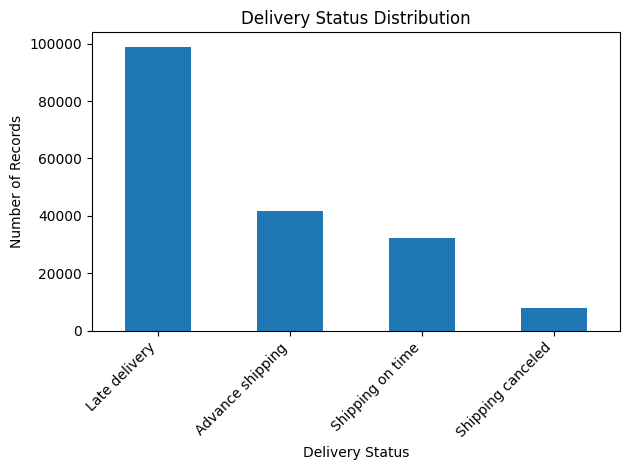

In [9]:
# Bar chart: Delivery Status
delivery_status_counts.plot(kind="bar")
plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Date Range Review

The order and shipping date fields are converted to datetime format. This helps determine the historical period covered by the dataset and prepares the data for joining to weather observations by date.


In [10]:
# Convert date fields
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"], errors="coerce")
df["shipping_date"] = pd.to_datetime(df["shipping date (DateOrders)"], errors="coerce")

print("Order date range:")
print(df["order_date"].min(), "to", df["order_date"].max())

print("\nShipping date range:")
print(df["shipping_date"].min(), "to", df["shipping_date"].max())

print("\nMissing converted order dates:", df["order_date"].isna().sum())
print("Missing converted shipping dates:", df["shipping_date"].isna().sum())

Order date range:
2015-01-01 00:00:00 to 2018-01-31 23:38:00

Shipping date range:
2015-01-03 00:00:00 to 2018-02-06 22:14:00

Missing converted order dates: 0
Missing converted shipping dates: 0


## 7. Geographic Scope

Because the approved research question focuses on U.S. shipment delays, the dataset must be filtered to U.S. orders. In this dataset, the United States appears as `Estados Unidos`, so the cleaning process will need to standardize this value.


In [11]:
# Top order countries
df["Order Country"].value_counts().head(20)

Order Country
Estados Unidos          24840
Francia                 13222
México                  13172
Alemania                 9564
Australia                8497
Brasil                   7987
Reino Unido              7302
China                    5758
Italia                   4989
India                    4783
Indonesia                4204
España                   3868
El Salvador              3726
República Dominicana     3669
Honduras                 3629
Cuba                     3534
Turquía                  3395
Nicaragua                3046
Guatemala                2778
Nigeria                  2309
Name: count, dtype: int64

In [12]:
# Filter to United States orders
us_df = df[df["Order Country"] == "Estados Unidos"].copy()

print(f"U.S. order records: {us_df.shape[0]:,}")
print(f"U.S. order columns: {us_df.shape[1]:,}")
us_df.head()

U.S. order records: 24,840
U.S. order columns: 55


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,order_date,shipping_date
55,PAYMENT,2,2,22.41,74.680000,Shipping on time,0,13,Electronics,Caguas,Puerto Rico,XXXXXXXXX,Mary,3296,Smith,XXXXXXXXX,Home Office,PR,8205 Silver Grove Row,725.0,3,Footwear,18.234663,-66.370598,USCA,Pasco,Estados Unidos,3296,6/11/2016 15:12,36146,278,15.300000,0.17,90273,44.990002,0.30,2,89.980003,74.680000,22.41,West of USA,Washington,PENDING_PAYMENT,99301.0,278,13,NaN,http://images.acmesports.sports/Under+Armour+M...,Under Armour Men's Compression EV SL Slide,44.990002,0,6/13/2016 15:12,Second Class,2016-06-11 15:12:00,2016-06-13 15:12:00
56,PAYMENT,5,2,25.24,90.150002,Late delivery,1,12,Boxing & MMA,Caguas,Puerto Rico,XXXXXXXXX,Frances,3182,Smith,XXXXXXXXX,Home Office,PR,7786 Middle Private,725.0,3,Footwear,18.262682,-66.370499,USCA,Los Angeles,Estados Unidos,3182,8/24/2016 21:45,41234,249,19.790001,0.18,102921,54.970001,0.28,2,109.940002,90.150002,25.24,West of USA,California,PENDING_PAYMENT,90049.0,249,12,NaN,http://images.acmesports.sports/Under+Armour+W...,Under Armour Women's Micro G Skulpt Running S,54.970001,0,8/29/2016 21:45,Second Class,2016-08-24 21:45:00,2016-08-29 21:45:00
57,PAYMENT,6,2,30.57,117.580002,Late delivery,1,17,Cleats,Caguas,Puerto Rico,XXXXXXXXX,Alice,7864,Smith,XXXXXXXXX,Home Office,PR,4294 High Passage,725.0,4,Apparel,18.282795,-66.370560,USCA,San Francisco,Estados Unidos,7864,4/13/2016 10:12,32090,365,2.400000,0.02,80250,59.990002,0.26,2,119.980003,117.580002,30.57,West of USA,California,PENDING_PAYMENT,94110.0,365,17,NaN,http://images.acmesports.sports/Perfect+Fitnes...,Perfect Fitness Perfect Rip Deck,59.990002,0,4/19/2016 10:12,Second Class,2016-04-13 10:12:00,2016-04-19 10:12:00
58,PAYMENT,4,2,46.07,95.980003,Late delivery,1,17,Cleats,Caguas,Puerto Rico,XXXXXXXXX,Kyle,11169,Thomas,XXXXXXXXX,Home Office,PR,5274 Easy Beach,725.0,4,Apparel,18.274662,-66.370583,USCA,Overland Park,Estados Unidos,11169,5/22/2016 14:10,34773,365,24.000000,0.20,86866,59.990002,0.48,2,119.980003,95.980003,46.07,US Center,Kansas,PENDING_PAYMENT,66212.0,365,17,NaN,http://images.acmesports.sports/Perfect+Fitnes...,Perfect Fitness Perfect Rip Deck,59.990002,0,5/26/2016 14:10,Second Class,2016-05-22 14:10:00,2016-05-26 14:10:00
183,TRANSFER,5,4,28.85,128.220001,Shipping canceled,0,13,Electronics,Freeport,EE. UU.,XXXXXXXXX,Patricia,1509,Petersen,XXXXXXXXX,Consumer,NY,3675 Emerald Goose Bank,11520.0,3,Footwear,40.654865,-73.587074,USCA,Houston,Estados Unidos,1509,5/8/2016 17:42,33824,278,6.750000,0.05,84424,44.990002,0.23,3,134.970001,128.220001,28.85,US Center,Texas,SUSPECTED_FRAUD,77041.0,278,13,NaN,http://images.acmesports.sports/Under+Armour+M...,Under Armour Men's Compression EV SL Slide,44.990002,0,5/13/2016 17:42,Standard Class,2016-05-08 17:42:00,2016-05-13 17:42:00


In [13]:
# Date range for U.S. records
print("U.S. order date range:")
print(us_df["order_date"].min(), "to", us_df["order_date"].max())

print("\nU.S. shipping date range:")
print(us_df["shipping_date"].min(), "to", us_df["shipping_date"].max())

U.S. order date range:
2016-04-01 20:22:00 to 2016-08-25 17:01:00

U.S. shipping date range:
2016-04-03 21:47:00 to 2016-08-31 15:37:00


## 8. U.S. State Distribution

The dataset contains U.S. states, but some state names are listed in Spanish. These values will be standardized during the transformation phase so they can be accurately joined to weather data.


In [14]:
# Top states by U.S. order volume
state_counts = us_df["Order State"].value_counts().head(20)
state_counts

Order State
California            4966
Nueva York            2753
Texas                 2446
Pensilvania           1406
Washington            1272
Illinois              1237
Ohio                  1122
Florida                941
Carolina del Norte     611
Michigan               610
Arizona                555
Virginia               550
Colorado               475
Georgia                475
Tennessee              454
Indiana                398
Kentucky               359
Massachusetts          337
Nueva Jersey           324
Wisconsin              307
Name: count, dtype: int64

In [20]:
# Number of unique U.S. cities
unique_cities = us_df["Order City"].nunique()

# List all unique cities
cities = sorted(us_df["Order City"].dropna().unique())

print(f"Unique U.S. cities: {unique_cities:,}")
print(cities)

Unique U.S. cities: 510
['Aberdeen', 'Abilene', 'Akron', 'Albuquerque', 'Alexandria', 'Allen', 'Allentown', 'Altoona', 'Amarillo', 'Anaheim', 'Andover', 'Ann Arbor', 'Antioch', 'Apopka', 'Apple Valley', 'Appleton', 'Arlington', 'Arlington Heights', 'Arvada', 'Asheville', 'Athens', 'Atlanta', 'Atlantic City', 'Auburn', 'Aurora', 'Austin', 'Avondale', 'Bakersfield', 'Baltimore', 'Bangor', 'Bayonne', 'Beaumont', 'Bedford', 'Belleville', 'Bellevue', 'Bellingham', 'Bethlehem', 'Beverly', 'Billings', 'Bloomington', 'Boca Raton', 'Boise', 'Bolingbrook', 'Bossier City', 'Bowling Green', 'Boynton Beach', 'Bozeman', 'Brentwood', 'Bridgeton', 'Bristol', 'Broken Arrow', 'Broomfield', 'Brownsville', 'Bryan', 'Buffalo', 'Buffalo Grove', 'Bullhead City', 'Burbank', 'Burlington', 'Caldwell', 'Camarillo', 'Cambridge', 'Canton', 'Carlsbad', 'Carol Stream', 'Carrollton', 'Cary', 'Cedar Hill', 'Cedar Rapids', 'Champaign', 'Chandler', 'Charlotte', 'Charlottesville', 'Chattanooga', 'Chesapeake', 'Chester', 

In [33]:
# Top 25 cities by order count

top_25_cities = us_df["Order City"].value_counts().head(25)
print(top_25_cities)

Order City
New York City    2202
Los Angeles      1845
Philadelphia     1302
San Francisco    1297
Seattle          1066
Houston           875
Chicago           789
Columbus          550
San Diego         425
Springfield       379
Dallas            374
Jacksonville      277
Detroit           276
Newark            244
Richmond          227
Columbia          226
San Antonio       187
Aurora            175
Jackson           169
Louisville        168
Phoenix           157
Long Beach        150
Arlington         150
Miami             140
Henderson         138
Name: count, dtype: int64


In [22]:
cities_per_state = (
    us_df.groupby("Order State")["Order City"]
    .nunique()
    .sort_values(ascending=False)
)

cities_per_state.head(20)

Order State
California            79
Texas                 52
Florida               33
Illinois              31
Ohio                  24
Michigan              21
Nueva Jersey          18
Nueva York            18
Washington            17
Carolina del Norte    17
Indiana               15
Massachusetts         14
Colorado              14
Tennessee             14
Minnesota             13
Arizona               13
Virginia              13
Wisconsin             13
Georgia               11
Utah                  10
Name: Order City, dtype: int64

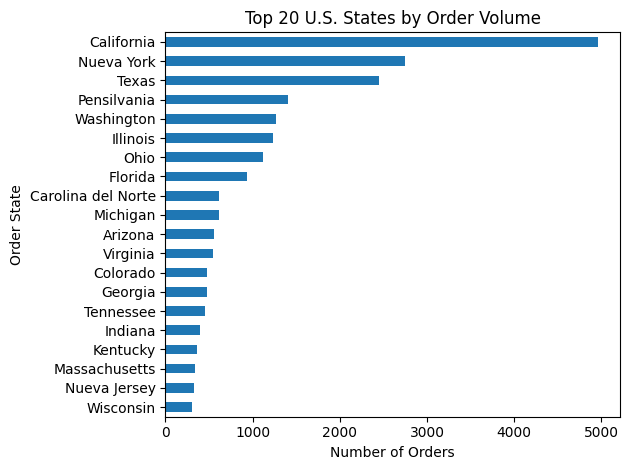

In [23]:
# Bar chart: Top U.S. states
state_counts.sort_values().plot(kind="barh")
plt.title("Top 20 U.S. States by Order Volume")
plt.xlabel("Number of Orders")
plt.ylabel("Order State")
plt.tight_layout()
plt.show()

## 9. U.S. Late Delivery Profile

This step checks late delivery patterns within the U.S. subset only. These values will become part of the baseline analysis before weather data is integrated.


In [24]:
# Delivery status for U.S. orders
us_df["Delivery Status"].value_counts(dropna=False)

Delivery Status
Late delivery        13670
Advance shipping      5549
Shipping on time      4501
Shipping canceled     1120
Name: count, dtype: int64

In [25]:
# U.S. late delivery rate
us_late_rate = us_df["Late_delivery_risk"].mean() * 100
print(f"U.S. late delivery risk rate: {us_late_rate:.2f}%")

U.S. late delivery risk rate: 55.03%


In [26]:
# Late delivery risk by top states
late_by_state = (
    us_df.groupby("Order State")
    .agg(
        total_orders=("Order Id", "count"),
        late_delivery_rate=("Late_delivery_risk", "mean")
    )
    .reset_index()
)

late_by_state["late_delivery_rate"] = (late_by_state["late_delivery_rate"] * 100).round(2)

late_by_state.sort_values("total_orders", ascending=False).head(20)

,Order State,total_orders,late_delivery_rate
3,California,4966,53.77
32,Nueva York,2753,57.90
41,Texas,2446,56.66
38,Pensilvania,1406,50.21
46,Washington,1272,51.57
15,Illinois,1237,55.21
35,Ohio,1122,53.21
12,Florida,941,55.05
4,Carolina del Norte,611,57.12
24,Michigan,610,52.46


## 10. Shipping Time Analysis

The dataset includes both actual shipping days and scheduled shipping days. These fields can be used to calculate whether the actual shipping time exceeded the expected shipping time.


In [27]:
# Create a calculated delay-days field
us_df["delay_days"] = us_df["Days for shipping (real)"] - us_df["Days for shipment (scheduled)"]

us_df[[
    "Order Id",
    "Delivery Status",
    "Late_delivery_risk",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "delay_days"
]].head(10)

,Order Id,Delivery Status,Late_delivery_risk,Days for shipping (real),Days for shipment (scheduled),delay_days
55,36146,Shipping on time,0,2,2,0
56,41234,Late delivery,1,5,2,3
57,32090,Late delivery,1,6,2,4
58,34773,Late delivery,1,4,2,2
183,33824,Shipping canceled,0,5,4,1
184,31364,Shipping canceled,0,5,4,1
185,40495,Shipping canceled,0,6,4,2
186,31364,Shipping canceled,0,5,4,1
187,34506,Shipping canceled,0,2,4,-2
188,33607,Shipping canceled,0,3,4,-1


In [28]:
# Summary statistics for shipping days and delay days
us_df[[
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "delay_days"
]].describe()

,Days for shipping (real),Days for shipment (scheduled),delay_days
count,24840.000000,24840.000000,24840.000000
mean,3.490620,2.914895,0.575725
std,1.630754,1.380535,1.483969
min,0.000000,0.000000,-2.000000
25%,2.000000,2.000000,0.000000
50%,3.000000,4.000000,1.000000
75%,5.000000,4.000000,1.000000
max,6.000000,4.000000,4.000000


In [29]:
# Average delay days by delivery status
us_df.groupby("Delivery Status")["delay_days"].mean().sort_values(ascending=False)

Delivery Status
Late delivery        1.619312
Shipping canceled    0.426786
Shipping on time     0.000000
Advance shipping    -1.498108
Name: delay_days, dtype: float64

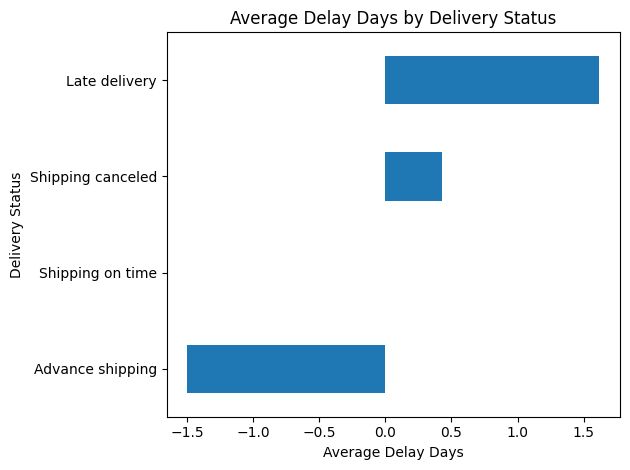

In [30]:
# Bar chart: Average delay days by delivery status
us_df.groupby("Delivery Status")["delay_days"].mean().sort_values().plot(kind="barh")
plt.title("Average Delay Days by Delivery Status")
plt.xlabel("Average Delay Days")
plt.ylabel("Delivery Status")
plt.tight_layout()
plt.show()

## 11. Shipping Mode and Late Delivery

Shipping mode may influence late delivery risk and should be retained as a control variable in the analytical dataset.


In [31]:
shipping_mode_summary = (
    us_df.groupby("Shipping Mode")
    .agg(
        total_orders=("Order Id", "count"),
        late_delivery_rate=("Late_delivery_risk", "mean"),
        avg_delay_days=("delay_days", "mean")
    )
    .reset_index()
)

shipping_mode_summary["late_delivery_rate"] = (shipping_mode_summary["late_delivery_rate"] * 100).round(2)
shipping_mode_summary["avg_delay_days"] = shipping_mode_summary["avg_delay_days"].round(2)

shipping_mode_summary.sort_values("late_delivery_rate", ascending=False)

,Shipping Mode,total_orders,late_delivery_rate,avg_delay_days
0,First Class,3824,95.29,1.00
2,Second Class,4939,76.70,1.97
1,Same Day,1401,44.97,0.45
3,Standard Class,14676,38.21,0.01


## 12. Candidate Fields for ETL Pipeline

The following fields are likely to be used in the final ETL pipeline and analytical database. These fields support shipment identification, geographic joining, date-based weather integration, delivery performance analysis, and dashboard creation.


In [32]:
candidate_columns = [
    "Order Id",
    "Order Customer Id",
    "order_date",
    "shipping_date",
    "Order Country",
    "Order State",
    "Order City",
    "Order Zipcode",
    "Market",
    "Order Region",
    "Shipping Mode",
    "Delivery Status",
    "Late_delivery_risk",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "delay_days",
    "Sales",
    "Order Profit Per Order",
    "Category Name",
    "Product Name"
]

candidate_profile = pd.DataFrame({
    "column": candidate_columns,
    "missing_count": [us_df[col].isna().sum() for col in candidate_columns],
    "missing_percent": [round(us_df[col].isna().mean() * 100, 2) for col in candidate_columns],
    "unique_values": [us_df[col].nunique(dropna=True) for col in candidate_columns]
})

candidate_profile

,column,missing_count,missing_percent,unique_values
0,Order Id,0,0.0,8270
1,Order Customer Id,0,0.0,6102
2,order_date,0,0.0,8270
3,shipping_date,0,0.0,8019
4,Order Country,0,0.0,1
5,Order State,0,0.0,48
6,Order City,0,0.0,510
7,Order Zipcode,0,0.0,609
8,Market,0,0.0,1
9,Order Region,0,0.0,4


## 13. Initial EDA Findings

Based on the initial review:

1. The dataset contains order, product, customer, and shipping information that can support shipment delay analysis.
2. The dataset includes a built-in late delivery indicator, `Late_delivery_risk`, which can be used as the primary outcome variable.
3. U.S. order records are available, but the United States is listed as `Estados Unidos`.
4. Some U.S. state names are listed in Spanish and will need to be standardized.
5. The U.S. subset provides enough records to support analysis.
6. Date fields can be converted successfully and used for time-based integration with weather data.
7. The next ETL step will be to standardize location fields, select the final shipment fields, and prepare the data for integration with NOAA weather observations.


## 14. Next Steps

The next phase of the project will:

1. Create a cleaned U.S. shipment dataset.
2. Standardize country and state names.
3. Select the final fields needed for the analytical database.
4. Design the SQLite database schema.
5. Extract historical weather data from NOAA.
6. Join shipment records to weather records by location and date.
7. Load the final analytical dataset into SQLite for SQL-based analysis and Power BI reporting.


In [34]:
# Count U.S. records by year

us_df["shipment_year"] = us_df["shipping_date"].dt.year

us_df["shipment_year"].value_counts().sort_index()

shipment_year
2016    24840
Name: count, dtype: int64

In [35]:
# Orders by month

us_df["shipment_month"] = us_df["shipping_date"].dt.month

us_df["shipment_month"].value_counts().sort_index()

shipment_month
4    4418
5    5197
6    5102
7    5296
8    4827
Name: count, dtype: int64

In [36]:
top_states = (
    us_df["Order State"]
    .value_counts()
    .reset_index()
)

top_states.columns = ["state", "orders"]

top_states.head(15)

,state,orders
0,California,4966
1,Nueva York,2753
2,Texas,2446
3,Pensilvania,1406
4,Washington,1272
5,Illinois,1237
6,Ohio,1122
7,Florida,941
8,Carolina del Norte,611
9,Michigan,610
